# Fase 1: Preparación del conjunto de datos

In [1]:
# Importar dependencias.
import constants
import numpy as np
import optuna
import pandas as pd
import torch
import warnings
from IPython.display import display
from pypots.imputation import SAITS
from pypots.optim import Adam
from sklearn.metrics import mean_absolute_error, root_mean_squared_error
from sklearn.preprocessing import StandardScaler, MinMaxScaler, RobustScaler
from util import chart_util, csv_util, date_util

# No mostrar mensajes de advertencia.
optuna.logging.set_verbosity(optuna.logging.ERROR)
warnings.filterwarnings('ignore')


████████╗██╗███╗   ███╗███████╗    ███████╗███████╗██████╗ ██╗███████╗███████╗    █████╗ ██╗
╚══██╔══╝██║████╗ ████║██╔════╝    ██╔════╝██╔════╝██╔══██╗██║██╔════╝██╔════╝   ██╔══██╗██║
   ██║   ██║██╔████╔██║█████╗█████╗███████╗█████╗  ██████╔╝██║█████╗  ███████╗   ███████║██║
   ██║   ██║██║╚██╔╝██║██╔══╝╚════╝╚════██║██╔══╝  ██╔══██╗██║██╔══╝  ╚════██║   ██╔══██║██║
   ██║   ██║██║ ╚═╝ ██║███████╗    ███████║███████╗██║  ██║██║███████╗███████║██╗██║  ██║██║
   ╚═╝   ╚═╝╚═╝     ╚═╝╚══════╝    ╚══════╝╚══════╝╚═╝  ╚═╝╚═╝╚══════╝╚══════╝╚═╝╚═╝  ╚═╝╚═╝
ai4ts v0.0.3 - building AI for unified time-series analysis, https://time-series.ai 



## 1. Introducción

El objetivo del TFM (Trabajo Fin de Máster) es realizar un análisis comparativo de diferentes modelos de inteligencia artificial para detectar anomalías que repercuten en el deterioro del pavimiento de las carreteras. En esta fase, se obtendrá el conjunto de datos inicial para entrenar y validar los modelos de inteligencia artificial. Sin embargo, los datos recopilados suelen tener impurezas (valores nulos, corruptos o duplicados) y, por tanto, aún no son óptimos para proceder con el entrenamiento. Por ello, es necesario analizarlos y limpiar las impurezas detectadas. También, si hiciera falta, se imputarán los valores faltantes o se eliminarán aquellos innecesarios.

## 2. Recopilación de datos

El conjunto de datos estará formado por los factores principales del deterioro de pavimentos. Para ello, se han seleccionado los **datos diarios de tráfico** (vehículos ligeros y pesados) y **meteorológicos** (temperatura, precipitaciones, radiación ultravioleta, etc.) entre **2018** y **2025** de dos ciudades neozelandesas: **Auckland** y **Christchurch**. Su elección no ha sido arbitraria, sino que son dos ciudades diferentes en cuanto al tráfico y el clima, lo que aportará variabilidad.

<div style="display: flex;">
    <figure>
        <img src="./img/Auckland.png" alt="Mapa de Auckland" style="width: 650px; height: auto;">
        <figcaption style="text-align:center; font-size:25px; font-weight:bold;">Auckland</figcaption>
    </figure>
    <figure>
        <img src="./img/Christchurch.png" alt="Mapa de Christchurch" style="width: 650px; height: auto;">
        <figcaption style="text-align:center; font-size:25px; font-weight:bold;">Christchurch</figcaption>
    </figure>
</div>

Los datos de tráfico recopilados proceden del sistema TMS (Traffic Monitoring System). Éste es gestionado por NZTA (New Zealand Transport Agency), que es la agencia gubernamental responsable del transporte terrestre. La instalación y el mantenimiento de los sensores es competencia de un proveedor. Además, también se encarga de recopilar los datos y reportarlos frecuentemente a TMS. Éste, a su vez, se encarga de validarlos para garantizar la coherencia. En el caso de que no pase la validación, se solicita al proveedor su subsanación. Si no se subsanan, el día en cuestión se queda sin imputar. También existen incidencias técnicas o coyunturales que pueden provocar lo mismo. Por tanto, dado que es inevitable que falten datos para algunos días, será necesario realizar imputaciones. Para ello, además de los datos meteorológicos, es necesario conocer los días festivos u otros eventos como el confinamiento por COVID-19 que afectan al tráfico.

Dada la cantidad de información necesaria, las fuentes de los datos son diversas. Por ello, se presentan en varios ficheros CSV, divididos por ciudad:
- `lockdown_days`: día de inicio y fin de los confinamientos para los años 2020 y 2021. Los datos para crear el fichero proceden del artículo [COVID-19 pandemic in New Zealand](https://en.wikipedia.org/wiki/COVID-19_pandemic_in_New_Zealand).
- `public_holidays`: días festivos (nacionales y locales). Los datos para crear el fichero proceden del sitio web [NZ Public Holidays](https://publicholiday.co.nz).
- `sections`: las secciones de carretera seleccionadas (identificadores, número de carriles y descripción).
- `traffic`: tráfico diario, dividido por dirección, carril y tipo de vehículo (ligero y pesado). El fichero CSV fue descargado desde [TMS daily traffic counts API](https://opendata-nzta.opendata.arcgis.com/datasets/tms-daily-traffic-counts-api/explore).
- `weather`: datos meteorológicos diarios. El fichero CSV fue descargado desde [Visual Crossing (weather API for businesses and developers)](https://www.visualcrossing.com/).

Si observamos una carretera por su perfil transversal, destacan tres partes:
- **Carril**: cada banda longitudinal destinada al tránsito de una sola fila de vehículos.
- **Calzada**: parte central dispuesta para la circulación de vehículos. Está asociada a un sentido de circulación y tiene uno o más carriles.
- **Sección**: punto de una carretera formado por dos calzadas.

<div style="display: flex;">
    <figure>
        <img src="./img/perfil-transversal-carretera.png" alt="Gráfico del perfil transversal de una carretera" style="width: 650px; height: auto;">
        <figcaption style="text-align:center; font-size:25px; font-weight:bold;">Perfil transversal de una carretera</figcaption>
    </figure>
</div>

Para trabajar con todos los datos recopilados, es necesario definir las funciones que los carguen.

In [2]:
def load_lockdown_days(city):
    df_lockdown_days = csv_util.read(f'dataset/raw_data/lockdown_days/{city}_lockdown_days.csv',
                                     usecols=['start_date', 'end_date'],
                                     date_formats=[('start_date', '%d/%m/%Y'), ('end_date', '%d/%m/%Y')])
    df_lockdown_days = date_util.create_ranges(df_lockdown_days, 'start_date', 'end_date')

    return df_lockdown_days

def load_public_holidays(city):
    df_public_holidays = csv_util.read(f'dataset/raw_data/public_holidays/{city}_public_holidays.csv',
                                       usecols=['date'],
                                       date_formats=[('date', '%d/%m/%Y')])

    return df_public_holidays

def load_sections(city):
    df_sections = csv_util.read(f'dataset/raw_data/sections/{city}_sections.csv',
                                usecols=['section_id', 'dir_1', 'dir_2', 'lanes', 'description'],
                                dtype={'section_id':int, 'dir_1':int, 'dir_2':int, 'lanes':int, 'description':str})

    return df_sections

def load_traffic(city):
    df_traffic = csv_util.read(f'dataset/raw_data/traffic/{city}_traffic.csv',
                               usecols=['Start Date', 'Site Alias', 'Class Weight', 'Lane Number', 'Flow Direction', 'Traffic Count'],
                               dtype={'Site Alias':int, 'Class Weight':str, 'Lane Number':int, 'Flow Direction':int, 'Traffic Count':float},
                               date_formats=[('Start Date', '%m/%d/%Y %I:%M:%S %p')])

    # Establecer hora 00:00:00.
    df_traffic['Start Date'] = pd.to_datetime(df_traffic['Start Date']).dt.normalize()

    # Solo registros de tráfico para los años de estudio.
    df_traffic = df_traffic[df_traffic['Start Date'].between(constants.START_DATE, constants.END_DATE)]

    return df_traffic

def load_weather(city):
    df_weather = csv_util.read(f'dataset/raw_data/weather/{city}_weather.csv',
                               usecols=['datetime', 'tempmax', 'tempmin', 'precip', 'windspeed', 'visibility', 'solarradiation', 'uvindex', 'sunrise', 'sunset'],
                               dtype={'tempmax':float, 'tempmin':float, 'precip':float, 'windspeed':float, 'visibility':float, 'solarradiation':float, 'uvindex':float},
                               date_formats=[('datetime', '%Y-%m-%d'), ('sunrise', '%Y-%m-%dT%H:%M:%S'), ('sunset', '%Y-%m-%dT%H:%M:%S')])

    # Solo registros meteorológicos para los años de estudio.
    df_weather = df_weather[df_weather['datetime'].between(constants.START_DATE, constants.END_DATE)]

    # Es necesario saber si son vientos fuertes.
    df_weather['strong_wind'] = (df_weather['windspeed'] >= constants.STRONG_WIND).astype(int)

    # Calcular horas de sol.
    df_weather['sunny_hours'] = ((df_weather['sunset'] - df_weather['sunrise']) / pd.to_timedelta('1h')).round(1)

    # Eliminar características innecesarias.
    df_weather = df_weather.drop(columns=['windspeed', 'sunrise', 'sunset'])

    return df_weather

## 3. Análisis de datos

Se analizarán los datos de los ficheros descargados (tráfico y meteorología). No será necesario para los otros porque son de elaboración propia. Dado que se va a emplear modelos de series temporales, hay que conocer la cobertura (ratio entre días con datos y días totales). Además, se detectarán valores nulos o duplicados.

Para los datos de tráfico, se filtrará por ciudad, tipo de tráfico, sección y dirección, y se hará una media de los días con datos para los carriles. No es necesario comprobar si existen valores duplicados o nulos porque el proveedor ya garantiza que no hay.

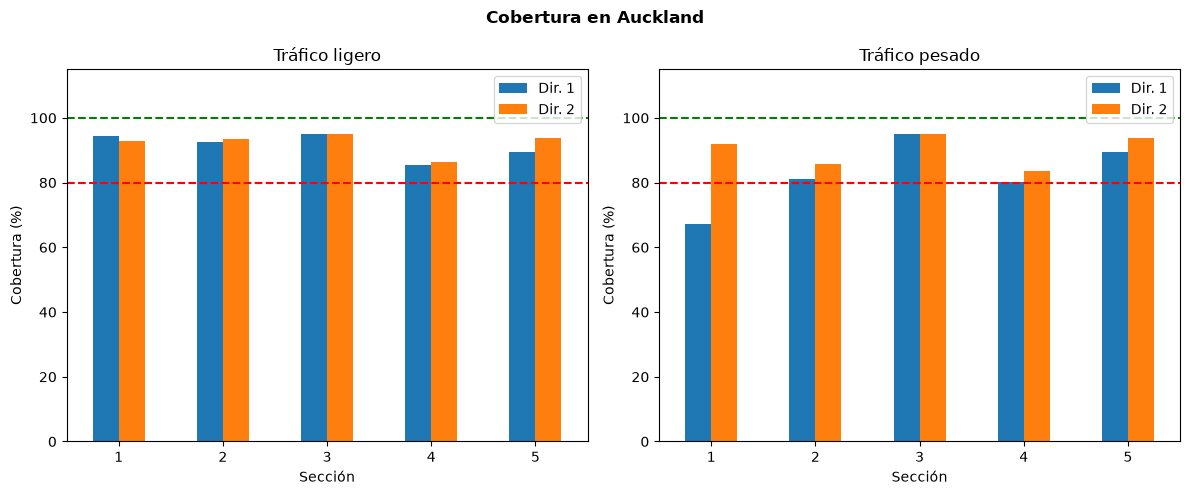

--------------------------------------------------
 Cobertura media en Auckland 
--------------------------------------------------


,Tráfico,Dirección,Media
0,Ligero,1,91.4 %
1,Ligero,2,92.3 %
2,Pesado,1,82.6 %
3,Pesado,2,90.0 %


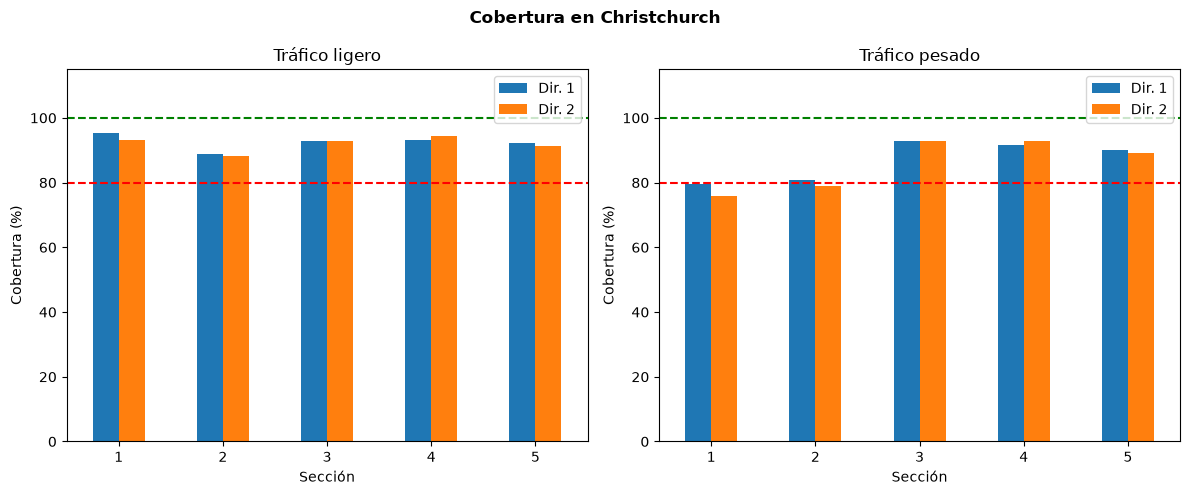

--------------------------------------------------
 Cobertura media en Christchurch 
--------------------------------------------------


,Tráfico,Dirección,Media
0,Ligero,1,92.4 %
1,Ligero,2,92.0 %
2,Pesado,1,87.0 %
3,Pesado,2,85.9 %


In [3]:
total_days = date_util.count_days(constants.START_DATE, constants.END_DATE)

def calculate_traffic_coverage(df_traffic, roadway_id, dir_id, total_days):
    df_section_traffic = df_traffic[(df_traffic['Site Alias'] == roadway_id) & (df_traffic['Flow Direction'] == dir_id)]

    return round((df_section_traffic.groupby('Lane Number')['Start Date'].nunique().mean() / total_days) * 100, 1)

for city in constants.CITIES:
    light_traffic_coverages_1, light_traffic_coverages_2, heavy_traffic_coverages_1, heavy_traffic_coverages_2 = [], [], [], []

    # Leer fichero CSV con datos de tráfico.
    df_traffic = load_traffic(city)
    df_traffic = df_traffic.drop(columns=['Traffic Count'])

    # Filtrar por tipo de tráfico para mejorar el rendimiento.
    df_light_traffic = df_traffic[df_traffic['Class Weight'] == 'Light']
    df_heavy_traffic = df_traffic[df_traffic['Class Weight'] == 'Heavy']

    # Leer fichero CSV con datos de secciones.
    df_sections = load_sections(city)
    num_sections = len(df_sections)

    # Calcular cobertura por sección.
    for i in df_sections.index:
        light_traffic_coverages_1.append(calculate_traffic_coverage(df_light_traffic, df_sections['dir_1'][i], 1, total_days))
        light_traffic_coverages_2.append(calculate_traffic_coverage(df_light_traffic, df_sections['dir_2'][i], 2, total_days))
        heavy_traffic_coverages_1.append(calculate_traffic_coverage(df_heavy_traffic, df_sections['dir_1'][i], 1, total_days))
        heavy_traffic_coverages_2.append(calculate_traffic_coverage(df_heavy_traffic, df_sections['dir_2'][i], 2, total_days))

    # Mostrar resultados por ciudad, tipo de tráfico, sección y dirección.
    section_ids = range(1, num_sections+1)
    chart_util.show_multiple([{'Section':section_ids, 'Dir. 1':light_traffic_coverages_1, 'Dir. 2':light_traffic_coverages_2},
                              {'Section':section_ids, 'Dir. 1':heavy_traffic_coverages_1, 'Dir. 2':heavy_traffic_coverages_2}],
                               'Section', ['Dir. 1', 'Dir. 2'], y_lines=[100., 80.], main_title=f'Cobertura en {city.capitalize()}',
                               titles=['Tráfico ligero', 'Tráfico pesado'], x_label='Sección', y_label='Cobertura (%)')

    # Mostrar resultados por tipo de tráfico y dirección.
    print(f"{'-' * 50}\n Cobertura media en {city.capitalize()} \n{'-' * 50}")
    display(pd.DataFrame({'Tráfico': ['Ligero', 'Ligero', 'Pesado', 'Pesado'],
                          'Dirección': [1, 2, 1, 2],
                          'Media': [f'{(sum(light_traffic_coverages_1) / num_sections):.1f} %',
                                    f'{(sum(light_traffic_coverages_2) / num_sections):.1f} %',
                                    f'{(sum(heavy_traffic_coverages_1) / num_sections):.1f} %',
                                    f'{(sum(heavy_traffic_coverages_2) / num_sections):.1f} %']}))

Todas las secciones tienen una cobertura de más del 80% para el tráfico ligero e, incluso, algunos por encima del 90%. Sin embargo, para el tráfico pesado, los resultados son peores, pero la mayoría está por encima del 80%. Por tanto, en el siguiente apartado, se procederá a imputar los días restantes.

Para los datos meteorológicos, solo se tendrá en cuenta la cobertura por ciudad y si existen datos nulos.

In [4]:
for city in constants.CITIES:
    # Leer fichero CSV con datos meteorológicos.
    df_weather = load_weather(city)

    # Evitar fechas duplicadas.
    num_rows_1 = len(df_weather)
    df_weather = df_weather.drop_duplicates(subset=['datetime'])
    num_rows_2 = len(df_weather)

    # Obtener cálculos.
    coverage = round((len(df_weather) / total_days) * 100, 1)
    days_with_null_parameters = df_weather.isna().any(axis=1).sum()

    # Mostrar resultados por ciudad.
    print(f'Datos meteorológicos de {city.capitalize()}')
    print(f'- Cobertura: {coverage} %')
    print(f'- Días con algún parámetro a null: {days_with_null_parameters}')
    print(f'- Fechas duplicadas: {num_rows_1 > num_rows_2}\n')

Datos meteorológicos de Auckland
- Cobertura: 100.0 %
- Días con algún parámetro a null: 0
- Fechas duplicadas: False

Datos meteorológicos de Christchurch
- Cobertura: 100.0 %
- Días con algún parámetro a null: 0
- Fechas duplicadas: False



Todos los datos son correctos y no faltan días. Por tanto, será muy útil para imputar los días de tráfico que faltan.

## 4. Limpieza de datos

Se imputarán los datos de tráfico que faltan a través del modelo SAITS. Éste está especializado en imputación en series temporales. Para ello, es necesario completar el conjunto de datos con los días que faltan y añadir características relevantes como días festivos o con confinamiento y datos meteorológicos. También se añadirá el número del día de la semana y del año, pero con codificación cíclica. De este modo, el modelo aprende, por ejemplo, que después del domingo viene el lunes.

Para evaluar las imputaciones del modelo, se calculará la media del tráfico por tipo, dirección y carril. Además, para este modelo, será necesario establecer la fecha como índice y, por tanto, cada fila representará un día concreto. Para ello, se crearán nuevas columnas que representen el tráfico registrado por calzada, dirección, carril y tipo.

In [5]:
def create_calendars(city):
    # Crear calendarios para los años de estudio.
    df_calendars = date_util.create_range(constants.START_DATE, constants.END_DATE)

    # Añadir codificación cíclica para días de la semana y año.
    df_calendars = date_util.add_cyclic_coding(df_calendars)

    # Añadir días festivos.
    df_public_holidays = load_public_holidays(city)
    df_calendars['holiday'] = df_calendars['date'].isin(df_public_holidays['date']).astype(int)

    # Añadir días con confinamientos.
    df_lockdown_days = load_lockdown_days(city)
    df_calendars['lockdown'] = df_calendars['date'].isin(df_lockdown_days['date']).astype(int)

    # Añadir datos meteorológicos.
    df_weather = load_weather(city)
    df_weather = df_weather.rename(columns={'datetime':'date'})
    df_calendars = pd.merge(df_calendars, df_weather, on='date', how='left')

    return df_calendars

def calculate_traffic_average(df_light_traffic, df_heavy_traffic):
    traffic_average = {}

    # Agrupar tráfico ligero por dirección y carril.
    light_group = df_light_traffic.groupby(['Flow Direction', 'Lane Number'])['Traffic Count'].mean()
    for (direction, lane), mean_val in light_group.items():
        traffic_average[f'Light_{direction}_{lane}'] = mean_val

    # Agrupar tráfico pesado por dirección y carril.
    heavy_group = df_heavy_traffic.groupby(['Flow Direction', 'Lane Number'])['Traffic Count'].mean()
    for (direction, lane), mean_val in heavy_group.items():
        traffic_average[f'Heavy_{direction}_{lane}'] = mean_val

    return traffic_average

def obtain_sections_by_roadway(df_sections):
    sections_by_roadway = {}

    for _, row in df_sections.iterrows():
        sections_by_roadway[row['dir_1']] = row['section_id']
        sections_by_roadway[row['dir_2']] = row['section_id']

    return sections_by_roadway

def pivot_traffic_table(city):
    df_sections = load_sections(city)
    sections_by_roadway = obtain_sections_by_roadway(df_sections)
    df_traffic = load_traffic(city)

    # En el caso de la ciudad de Christchurch, se utiliza un identificador de carril diferente para cada dirección.
    if city == 'christchurch':
        lanes_by_dir = dict(zip(df_sections['dir_2'], df_sections['lanes']))
        df_traffic['Lane Number'] = np.where(df_traffic['Flow Direction'] == 2, (df_traffic['Site Alias'].map(lanes_by_dir) * 2 + 1) - df_traffic['Lane Number'], df_traffic['Lane Number']).astype(int)

    # Obtener la media de tráfico por dirección, carril y tipo.
    traffic_average = calculate_traffic_average(df_traffic[df_traffic['Class Weight'] == 'Light'].copy(), df_traffic[df_traffic['Class Weight'] == 'Heavy'].copy())
    csv_util.save(pd.DataFrame(list(traffic_average.items()), columns=['category', 'average_traffic']), f'model/SAITS/stats/{city}_stats.csv', mode='w')

    # Crear identificador único (sección, calzada, dirección, carril y tipo de tráfico).
    df_traffic['section'] = df_traffic['Site Alias'].map(sections_by_roadway)
    df_traffic['id'] = ('id_' + df_traffic['section'].astype(str) + '_' + df_traffic['Site Alias'].astype(str) + '_' + df_traffic['Flow Direction'].astype(str) + '_' +
                        df_traffic['Lane Number'].astype(str) + '_' + df_traffic['Class Weight'])

    # Pivotar datos de tráfico y añadir días que faltan.
    df_traffic_wide = df_traffic.pivot(index='Start Date', columns='id', values='Traffic Count')
    df_traffic_wide = df_traffic_wide.asfreq('D')
    df_traffic_wide.index.name = 'date'

    return df_traffic_wide

A continuación, se obtendrán los conjuntos de datos, uno por cada ciudad, que procesará el modelo SAITS.

In [6]:
for city in constants.CITIES:
    # Transformar datos de tráfico para el modelo SAITS.
    df_traffic = pivot_traffic_table(city)

    # Cargar y quitar datos meteorológicos innecesarios para el modelo SAITS.
    df_calendars = create_calendars(city)
    df_calendars = df_calendars.drop(columns=['solarradiation', 'uvindex'])

    # Unir datos de tráfico con la meteorología.
    df_saits = df_traffic.merge(df_calendars, on='date', how='left')

    csv_util.save(df_saits, f'model/SAITS/dataset/{city}_dataset.csv', mode='w')

Antes de ejecutar el procedimiento para imputar los valores nulos de tráfico con el modelo SAITS, es necesario definir varias funciones auxiliares: dividir el conjunto de datos, normalización o estandarización de datos numéricos, así como revertir el proceso. También serán necesarias ventanas temporales.

In [7]:
def split_dataset(city):
    # Cargar datos, asignar índice y obtener solo columnas de tráfico.
    df = csv_util.read(f'model/SAITS/dataset/{city}_dataset.csv', date_formats=[('date', '%Y-%m-%d')])
    df = df.set_index('date')
    traffic_cols = [col for col in df.columns if col.startswith('id_')]

    # Dividir conjunto de datos en entrenamiento y validación.
    df_train = df[df.index.year < constants.SAITS_BOUNDARY_YEAR].copy()
    df_val = df[df.index.year >= constants.SAITS_BOUNDARY_YEAR].copy()

    # Añadir última ventana temporal del conjunto de entrenamiento para poder imputar los primeros días del conjunto de validación.
    cutoff_date = pd.to_datetime(f'{constants.SAITS_BOUNDARY_YEAR}-01-01') - pd.Timedelta(days=(constants.WINDOW_SIZE - 1))
    df_val = pd.concat([df_train[df_train.index >= cutoff_date].copy(), df_val], axis=0)

    return df_train, df_val, traffic_cols

def apply_scale(df_train, df_val, traffic_cols):
    # Estandarizar características con valores que siguen una distribución normal, donde el centro es la media.
    traffic_scaler = StandardScaler()
    df_train[traffic_cols] = traffic_scaler.fit_transform(df_train[traffic_cols])
    df_val[traffic_cols] = traffic_scaler.transform(df_val[traffic_cols])
    temperature_scaler = StandardScaler()
    temperature_cols = ['tempmax', 'tempmin']
    df_train[temperature_cols] = temperature_scaler.fit_transform(df_train[temperature_cols])
    df_val[temperature_cols] = temperature_scaler.transform(df_val[temperature_cols])

    # Normalizar características con valores con límites bien definidos.
    visibility_scaler = MinMaxScaler()
    visibility_cols = ['visibility', 'sunny_hours']
    df_train[visibility_cols] = visibility_scaler.fit_transform(df_train[visibility_cols])
    df_val[visibility_cols] = visibility_scaler.transform(df_val[visibility_cols])

    # Escalar características con muchos valores iguales a 0.
    precipitation_scaler = RobustScaler()
    precipitation_cols = ['precip']
    df_train[precipitation_cols] = precipitation_scaler.fit_transform(df_train[precipitation_cols])
    df_val[precipitation_cols] = precipitation_scaler.transform(df_val[precipitation_cols])

    return df_train, df_val, traffic_scaler

def reverse_scale(df_traffic, traffic_cols, traffic_scaler):
    df_traffic[traffic_cols] = traffic_scaler.inverse_transform(df_traffic[traffic_cols])

    # Por si hubiera algún valor imputado que fuera negativo.
    df_traffic[traffic_cols] = df_traffic[traffic_cols].clip(lower=0)

    return df_traffic

def create_windows(df):
    matrix = df.to_numpy(dtype=np.float32)
    windows = []

    for i in range(len(matrix) - constants.WINDOW_SIZE + 1):
        window = matrix[i : i + constants.WINDOW_SIZE]
        windows.append(window)

    # Convierte los datos en una tabla tridimensional
    # (ventanas, tamaño de la ventana y características).
    return np.array(windows)

Para el entrenamiento e imputación con el modelo SAITS, es necesario seleccionar los mejores hiperparámetros. Para ello, se utilizará la herramienta Optuna.

In [8]:
def objective_saits(trial, train_3d, val_3d, num_traffic_cols, city):
    # Crear copia para evitar perdida de información.
    val_3d_trial = val_3d.copy()

    # Hiperparámetros a optimizar.
    n_layers = trial.suggest_int('n_layers', 1, 3)
    d_model = trial.suggest_categorical('d_model', [64, 128, 256])
    n_heads = trial.suggest_categorical('n_heads', [2, 4, 8])
    d_k = d_model // n_heads
    d_v = d_model // n_heads
    d_ffn = trial.suggest_categorical('d_ffn', [128, 256, 512])
    batch_size = trial.suggest_categorical('batch_size', [16, 32, 64])
    lr = trial.suggest_float('lr', 1e-4, 1e-2, log=True)

    # Obtener coordenadas de datos reales solo de tráfico.
    traffic_val_subset = val_3d_trial[:, :, :num_traffic_cols]
    valid_indexes = np.where(~np.isnan(traffic_val_subset))

    # Descartar las primeras 'window_size - 1' ventanas que contienen días de diciembre.
    val_mask = valid_indexes[0] >= (constants.WINDOW_SIZE - 1)

    # Lista de ventanas.
    valid_windows = valid_indexes[0][val_mask]
    num_valid_points = len(valid_windows)

    # Lista de días dentro de las ventanas.
    valid_days = valid_indexes[1][val_mask]

    # Lista de columnas de tráfico (0 a num_traffic_cols - 1).
    valid_cols = valid_indexes[2][val_mask]

    # Seleccionar al azar un conjunto de datos válidos de tráfico para ocultarlos.
    indexes_to_hide = np.random.choice(num_valid_points, int(num_valid_points * constants.MISSING_VALUES), replace=False)
    hidden_coords = (valid_windows[indexes_to_hide],
                     valid_days[indexes_to_hide],
                     valid_cols[indexes_to_hide])
    real_values = traffic_val_subset[hidden_coords]

    # Asignar valores nulos solo en el bloque de tráfico.
    val_3d_trial[:, :, :num_traffic_cols][hidden_coords] = np.nan

    # Entrenar con número de épocas bajo para ir más rápido. Tampoco guardar los modelos para ir más rápido.
    saits_model = SAITS(n_steps=int(train_3d.shape[1]), n_features=int(train_3d.shape[2]), n_layers=n_layers,
                        d_model=d_model, n_heads=n_heads, d_k=d_k, d_v=d_v, d_ffn=d_ffn, batch_size=batch_size,
                        epochs=constants.NUM_EPOCHS_OPTUNA, optimizer=Adam(lr=lr), saving_path=f'model/SAITS/trial/optuna/{city}', verbose=False, device='cuda')
    saits_model.fit(train_set={'X':train_3d})

    # Imputar el conjunto de validación modificado.
    results = saits_model.predict({'X':val_3d_trial})
    imputation = results['imputation']

    # Calcular el error comparando solo los puntos ocultos.
    mae = mean_absolute_error(real_values, imputation[:, :, :num_traffic_cols][hidden_coords])
    print(f'Trial: {trial.number + 1}/{constants.NUM_TRIALS} | MAE: {mae:.4f}')

    # Eliminar la instancia del modelo. Limpiar la caché de la GPU.
    del saits_model
    torch.cuda.empty_cache()

    return mae

def fit_saits(study, train_3d, city):
    best_params = study.best_params
    saits_model = SAITS(n_steps=int(train_3d.shape[1]), n_features=int(train_3d.shape[2]), n_layers=best_params['n_layers'],
                        d_model=best_params['d_model'], n_heads=best_params['n_heads'], d_k=best_params['d_model'] // best_params['n_heads'],
                        d_v=best_params['d_model'] // best_params['n_heads'], d_ffn=best_params['d_ffn'], batch_size=best_params['batch_size'],
                        epochs=constants.NUM_EPOCHS_SAITS, optimizer=Adam(lr=best_params['lr']), saving_path=f'model/SAITS/trial/{city}', verbose=False, device='cuda')
    saits_model.fit(train_set={'X':train_3d})

    return saits_model

def impute_saits(saits_model, set_3d, df, trainset=False):
    # Imputar sobre el propio tensor.
    results = saits_model.predict({'X':set_3d})
    imputation_3d = results['imputation']
    index = None

    if trainset:
        # Extraer la primera ventana y, del resto de ventanas, solo el último día.
        imputation_2d = np.vstack([imputation_3d[0, :, :], imputation_3d[1:, -1, :]])
        index = df.index
    else:
        # Descartar los primeros días (que pertenecen a diciembre).
        indexes_2024 = df[df.index.year >= constants.SAITS_BOUNDARY_YEAR].index
        # Extraer exactamente los últimos días predichos por las ventanas de validación.
        imputation_2d = imputation_3d[-len(indexes_2024):, -1, :]
        # Extraer la matriz original.
        df = df.loc[indexes_2024].copy()
        index = indexes_2024

    # Transformar a matriz.
    matrix = df.to_numpy()
    # Solo si el valor original es nulo, se usa la imputación de SAITS.
    imputation_2d_final = np.where(np.isnan(matrix), imputation_2d, matrix)

    return pd.DataFrame(imputation_2d_final, columns=df.columns, index=index)

También es importante validar el modelo generado.

In [9]:
def split_traffic_by_categories(set_3d, cols):
    traffic_indexes_by_category, traffic_by_categories = {}, {}

    for index, col in enumerate(cols):
        if col.startswith('id_'):
            # Extraer identificadores de las columnas.
            ids = col.split('_')
            # Categoría formada por tipo de tráfico, dirección y carril.
            traffic_indexes_by_category.setdefault(f'{ids[5]}_{ids[3]}_{ids[4]}', []).append(index)

    for category, indexes in traffic_indexes_by_category.items():
        # Filtrar tensor por categorías.
        traffic_by_categories[category] = set_3d[:, :, indexes]

    return traffic_indexes_by_category, traffic_by_categories

def create_val_mask(val_3d, traffic_indexes_by_category, traffic_by_categories):
    # Crear máscara global vacía.
    val_mask = np.zeros_like(val_3d, dtype=bool)

    for category, indexes in traffic_indexes_by_category.items():
        # Identificar solo índices de tráfico.
        valid_indexes = np.argwhere(~np.isnan(traffic_by_categories[category]))

        # Seleccionar aleatoriamente los índices de los valores a evaluar.
        selected_indexes = valid_indexes[np.random.choice(len(valid_indexes), int(len(valid_indexes) * constants.MISSING_VALUES), replace=False)]

        # Transladar los índices seleccionados a la máscara global.
        for sample, seq, rel_col in selected_indexes:
            val_mask[sample, seq, indexes[rel_col]] = True

    return val_mask

def obtain_metrics(val_3d, imputed_3d, val_mask_traffic, traffic_indexes_by_category, traffic_col_indexes, city):
    all_metrics = {'category':[], 'mae':[], 'mae_std':[], 'rmse':[], 'wape':[]}

    for category, indexes in traffic_indexes_by_category.items():
        # Extraer índices absolutos globales a índices relativos dentro del bloque de tráfico.
        relative_indexes = [traffic_col_indexes.index(idx) for idx in indexes]

        # Extraer únicamente los puntos evaluados.
        sub_mask = val_mask_traffic[:, :, relative_indexes]
        y_true = val_3d[:, :, relative_indexes][sub_mask]
        y_pred = imputed_3d[:, :, relative_indexes][sub_mask]

        # Calcular las métricas.
        absolute_errors = np.abs(y_true - y_pred)
        sum_true = np.sum(y_true)
        mae = mean_absolute_error(y_true, y_pred)
        mae_std = np.std(absolute_errors)
        rmse = root_mean_squared_error(y_true, y_pred)
        wape = np.sum(absolute_errors) / sum_true if sum_true != 0.0 else 0.0

        # Almacenar métricas del carril.
        all_metrics['category'].append(category)
        all_metrics['mae'].append(mae)
        all_metrics['mae_std'].append(mae_std)
        all_metrics['rmse'].append(rmse)
        all_metrics['wape'].append(wape)

    csv_util.save(pd.DataFrame(all_metrics), f'model/SAITS/stats/{city}_SAITS_stats.csv', mode='w')

def evaluate_saits_by_lane(saits_model, val_3d, cols, traffic_scaler, city):
    # Establecer semillero.
    np.random.seed(42)

    # Obtener índices y tensores por categoría (tipo de tráfico, dirección y carril).
    traffic_indexes_by_category, traffic_by_categories = split_traffic_by_categories(val_3d, cols)

    # Crear máscara con elementos ocultos para evaluar.
    val_mask = create_val_mask(val_3d, traffic_indexes_by_category, traffic_by_categories)

    # Crear versión del tensor con valores nulos.
    val_3d_with_zeros = val_3d.copy()
    val_3d_with_zeros[val_mask] = np.nan

    # Imputar con SAITS.
    results = saits_model.predict({'X':val_3d_with_zeros})
    val_imputation_3d = results['imputation']

    # Filtrar por columnas solo de tráfico.
    traffic_col_indexes = [index for index, col in enumerate(cols) if col.startswith('id_')]
    val_3d_traffic = val_3d[:, :, traffic_col_indexes]
    val_imputation_3d_traffic = val_imputation_3d[:, :, traffic_col_indexes]
    val_mask_traffic = val_mask[:, :, traffic_col_indexes]

    # Aplanar a 2D para desestandarizar.
    shape_3d_traffic = val_3d_traffic.shape
    val_2d_traffic = val_3d_traffic.reshape(-1, shape_3d_traffic[-1])
    imputation_2d_traffic = val_imputation_3d_traffic.reshape(-1, shape_3d_traffic[-1])

    # Desestandarizar la matriz completa. Cada carril utiliza la propia.
    val_2d_traffic_final = traffic_scaler.inverse_transform(val_2d_traffic)
    imputation_2d_traffic_final = traffic_scaler.inverse_transform(imputation_2d_traffic)

    # Reconstruir a 3D para aplicar la máscara tridimensional.
    val_3d_traffic_final = val_2d_traffic_final.reshape(shape_3d_traffic)
    imputed_3d_traffic_final = imputation_2d_traffic_final.reshape(shape_3d_traffic)

    # Calcular métricas.
    obtain_metrics(val_3d_traffic_final, imputed_3d_traffic_final, val_mask_traffic, traffic_indexes_by_category, traffic_col_indexes, city)

Los datos de tráfico imputados se persistirán.

In [10]:
def save_imputed_traffic(df_saits, traffic_cols, city):
    # Convertir el índice 'date' en una columna más.
    df_saits = df_saits.reset_index()

    # Despivotar columnas de tráfico.
    df_temp = df_saits.melt(id_vars=['date'], value_vars=traffic_cols, var_name='traffic_ids', value_name='traffic')

    # Extraer calzada, dirección, carril y tipo de tráfico a partir de los identificadores.
    traffic_ids = df_temp['traffic_ids'].str.extract(r'id_(?P<section>\d+)_(?P<roadway>\d+)_(?P<direction>\d+)_(?P<lane>\d+)_(?P<class>Light|Heavy)')
    df_temp['city'] = city
    df_temp['section'] = traffic_ids['section']
    df_temp['roadway'] = traffic_ids['roadway']
    df_temp['direction'] = traffic_ids['direction']
    df_temp['lane'] = traffic_ids['lane']
    df_temp['class'] = traffic_ids['class'].map({'Heavy': 'heavy_traffic', 'Light': 'light_traffic'})

    # Repivotizar para tener el tráfico ligero y pesado en columnas separadas por fecha y carril.
    df_traffic = df_temp.pivot(index=['date', 'city', 'section', 'roadway', 'direction', 'lane'], columns='class', values='traffic').reset_index()
    df_traffic.columns.name = None

    csv_util.save(df_traffic, f'model/SAITS/result/{city}_traffic.csv', mode='w')

Para no saturar el sistema, se procederá cada ciudad independientemente.

In [11]:
def run_saits(city):
    print(f'Imputar tráfico en {city.capitalize()} con SAITS')
    print('1. Dividir conjunto de datos en entrenamiento y validación')
    df_train, df_val, traffic_cols = split_dataset(city)

    print('2. Normalizar/estandarizar datos numéricos')
    df_train, df_val, traffic_scaler = apply_scale(df_train, df_val, traffic_cols)

    print('3. Crear ventanas temporales')
    train_3d = create_windows(df_train)
    val_3d = create_windows(df_val)

    print('4. Buscar mejores hiperparámetros con Optuna')
    study = optuna.create_study(direction='minimize')
    study.optimize(lambda trial: objective_saits(trial, train_3d, val_3d, len(traffic_cols), city), n_trials=constants.NUM_TRIALS)

    print('5. Entrenar con los mejores hiperparámetros')
    saits_model = fit_saits(study, train_3d, city)

    print('6. Imputar valores nulos')
    df_train_final = impute_saits(saits_model, train_3d, df_train, True)
    df_val_final = impute_saits(saits_model, val_3d, df_val)

    print('7. Evaluar modelo')
    evaluate_saits_by_lane(saits_model, val_3d, df_val.columns.tolist(), traffic_scaler, city)

    print('8. Concatenar conjunto de entrenamiento y validación')
    df_final = pd.concat([df_train_final, df_val_final], axis=0)

    print('9. Desnormalizar/desestandarizar datos numéricos')
    df_final = reverse_scale(df_final, traffic_cols, traffic_scaler)

    print('10. Guardar datos imputados')
    save_imputed_traffic(df_final, traffic_cols, city)

    # Eliminar la instancia del modelo. Limpiar la caché de la GPU.
    del saits_model
    torch.cuda.empty_cache()
    print('FIN SAITS')

In [12]:
run_saits(constants.CITIES[0])

Imputar tráfico en Auckland con SAITS
1. Dividir conjunto de datos en entrenamiento y validación
2. Normalizar/estandarizar datos numéricos
3. Crear ventanas temporales
4. Buscar mejores hiperparámetros con Optuna
Trial: 1/20 | MAE: 0.1299
Trial: 2/20 | MAE: 0.1365
Trial: 3/20 | MAE: 0.1427
Trial: 4/20 | MAE: 0.1543
Trial: 5/20 | MAE: 0.1395
Trial: 6/20 | MAE: 0.1402
Trial: 7/20 | MAE: 0.1420
Trial: 8/20 | MAE: 0.1505
Trial: 9/20 | MAE: 0.1355
Trial: 10/20 | MAE: 0.4961
Trial: 11/20 | MAE: 0.1278
Trial: 12/20 | MAE: 0.1306
Trial: 13/20 | MAE: 0.1584
Trial: 14/20 | MAE: 0.1291
Trial: 15/20 | MAE: 0.1275
Trial: 16/20 | MAE: 0.6368
Trial: 17/20 | MAE: 0.1408
Trial: 18/20 | MAE: 0.1311
Trial: 19/20 | MAE: 0.1377
Trial: 20/20 | MAE: 0.1454
5. Entrenar con los mejores hiperparámetros
6. Imputar valores nulos
7. Evaluar modelo
8. Concatenar conjunto de entrenamiento y validación
9. Desnormalizar/desestandarizar datos numéricos
10. Guardar datos imputados
FIN SAITS


In [13]:
run_saits(constants.CITIES[1])

Imputar tráfico en Christchurch con SAITS
1. Dividir conjunto de datos en entrenamiento y validación
2. Normalizar/estandarizar datos numéricos
3. Crear ventanas temporales
4. Buscar mejores hiperparámetros con Optuna
Trial: 1/20 | MAE: 0.3040
Trial: 2/20 | MAE: 0.2889
Trial: 3/20 | MAE: 0.3056
Trial: 4/20 | MAE: 0.2753
Trial: 5/20 | MAE: 0.2832
Trial: 6/20 | MAE: 0.2911
Trial: 7/20 | MAE: 0.2914
Trial: 8/20 | MAE: 0.2607
Trial: 9/20 | MAE: 0.2840
Trial: 10/20 | MAE: 0.2916
Trial: 11/20 | MAE: 0.2782
Trial: 12/20 | MAE: 0.2689
Trial: 13/20 | MAE: 0.2674
Trial: 14/20 | MAE: 0.2820
Trial: 15/20 | MAE: 0.2768
Trial: 16/20 | MAE: 0.2637
Trial: 17/20 | MAE: 0.2749
Trial: 18/20 | MAE: 0.2893
Trial: 19/20 | MAE: 0.2756
Trial: 20/20 | MAE: 0.2720
5. Entrenar con los mejores hiperparámetros
6. Imputar valores nulos
7. Evaluar modelo
8. Concatenar conjunto de entrenamiento y validación
9. Desnormalizar/desestandarizar datos numéricos
10. Guardar datos imputados
FIN SAITS


A continuación, se mostrará la evaluación del modelo SAITS por ciudad.

In [15]:
def load_stats(city):
    df_stats = csv_util.read(f'model/SAITS/stats/{city}_stats.csv',
                             usecols=['category', 'average_traffic'],
                             dtype={'category':str, 'average_traffic':float})

    return df_stats

def load_saits_stats(city):
    df_saits_stats = csv_util.read(f'model/SAITS/stats/{city}_SAITS_stats.csv',
                                   usecols=['category', 'mae', 'mae_std', 'rmse', 'wape'],
                                   dtype={'category':str, 'mae':float, 'mae_std':float, 'rmse':float, 'wape':float})

    return df_saits_stats

for city in constants.CITIES:
    # Mezclar estadísticas generales con las de SAITS.
    df_stats = load_stats(city).set_index('category')
    df_saits_stats = load_saits_stats(city).set_index('category')
    df_full_stats = df_stats.join(df_saits_stats)

    # Extraer categorías (tipo de tráfico, dirección y carril).
    categories = df_full_stats.index.str.split('_', expand=True)

    # Mostrar estadísticas.
    print(f"{'-' * 50}\n Evaluación modelo SAITS de {city.capitalize()} \n{'-' * 50}")
    display(pd.DataFrame({'Tráfico': categories.get_level_values(0),
                          'Dirección': categories.get_level_values(1),
                          'Carril': categories.get_level_values(2),
                          'Media': df_full_stats['average_traffic'].map('{:.2f} veh/d'.format).values,
                          'MAE': (df_full_stats['mae'].map('{:.2f}'.format) + ' ± ' + df_full_stats['mae_std'].map('{:.2f} veh/d'.format)).values,
                          'nMAE': ((df_full_stats['mae'] / df_full_stats['average_traffic']) * 100).map('{:.2f} %'.format).values,
                          'RMSE': df_full_stats['rmse'].map('{:.2f} veh/d'.format).values,
                          'WAPE': (df_full_stats['wape'] * 100).map('{:.2f} %'.format).values}))

--------------------------------------------------
 Evaluación modelo SAITS de Auckland 
--------------------------------------------------


,Tráfico,Dirección,Carril,Media,MAE,nMAE,RMSE,WAPE
0,Light,1,1,13494.82 veh/d,416.87 ± 343.84 veh/d,3.09 %,540.37 veh/d,2.84 %
1,Light,1,2,15647.38 veh/d,415.91 ± 343.40 veh/d,2.66 %,539.35 veh/d,2.41 %
2,Light,1,3,16045.99 veh/d,308.06 ± 284.13 veh/d,1.92 %,419.09 veh/d,1.82 %
3,Light,1,4,18490.05 veh/d,496.97 ± 395.35 veh/d,2.69 %,635.05 veh/d,2.58 %
4,Light,2,1,12808.11 veh/d,277.15 ± 258.45 veh/d,2.16 %,378.96 veh/d,2.02 %
5,Light,2,2,13568.26 veh/d,363.75 ± 296.17 veh/d,2.68 %,469.07 veh/d,2.41 %
6,Light,2,3,17577.18 veh/d,301.87 ± 256.08 veh/d,1.72 %,395.86 veh/d,1.59 %
7,Light,2,4,20358.59 veh/d,387.04 ± 309.56 veh/d,1.90 %,495.61 veh/d,1.84 %
8,Heavy,1,1,1118.87 veh/d,46.01 ± 44.34 veh/d,4.11 %,63.90 veh/d,4.12 %
9,Heavy,1,2,858.47 veh/d,39.50 ± 36.49 veh/d,4.60 %,53.77 veh/d,4.29 %


--------------------------------------------------
 Evaluación modelo SAITS de Christchurch 
--------------------------------------------------


,Tráfico,Dirección,Carril,Media,MAE,nMAE,RMSE,WAPE
0,Light,1,1,7970.99 veh/d,335.23 ± 351.25 veh/d,4.21 %,485.54 veh/d,3.75 %
1,Light,1,2,5964.45 veh/d,356.14 ± 459.61 veh/d,5.97 %,581.45 veh/d,5.36 %
2,Light,2,1,7332.28 veh/d,284.20 ± 334.01 veh/d,3.88 %,438.56 veh/d,3.51 %
3,Light,2,2,6693.09 veh/d,339.12 ± 436.20 veh/d,5.07 %,552.51 veh/d,4.54 %
4,Heavy,1,1,811.90 veh/d,64.31 ± 78.07 veh/d,7.92 %,101.15 veh/d,7.31 %
5,Heavy,1,2,146.09 veh/d,28.26 ± 41.01 veh/d,19.35 %,49.80 veh/d,19.01 %
6,Heavy,2,1,717.04 veh/d,64.66 ± 94.05 veh/d,9.02 %,114.13 veh/d,7.79 %
7,Heavy,2,2,368.91 veh/d,35.22 ± 40.49 veh/d,9.55 %,53.66 veh/d,8.85 %
